# Simple Clustering with K-Means

This notebook uses a deterministic synthetic clustering toy problem to show how K-means partitions data into compact groups. It standardizes the feature space before fitting and plots the found centroids. The example is intentionally simple and self-contained, so it can run without any downloaded data.

In [1]:
import os
from pathlib import Path
import matplotlib.pyplot as plt
import numpy as np
from sklearn.cluster import KMeans
from sklearn.datasets import make_blobs
from sklearn.metrics import silhouette_score
from sklearn.preprocessing import StandardScaler

SEED = 41
OUTPUT_DIR = Path('generated/cluster-041'); OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
X, _ = make_blobs(n_samples=300, centers=3, cluster_std=1.0, random_state=SEED)
X_scaled = StandardScaler().fit_transform(X)
print('shape:', X_scaled.shape)

shape: (300, 2)


## 1. Fit a K-means model with three clusters

In [2]:
model = KMeans(n_clusters=3, n_init=10, random_state=SEED)
labels = model.fit_predict(X_scaled)
silhouette = silhouette_score(X_scaled, labels)
print(f'k=3 silhouette: {silhouette:.3f}')
print(f'inertia: {model.inertia_:.3f}')

k=3 silhouette: 0.809
inertia: 23.148


## 2. Visualize the partition and centroids

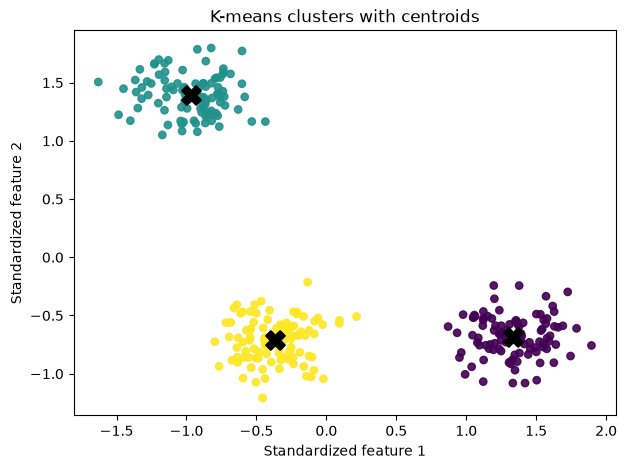

saved: generated\cluster-041\kmeans-clusters.png


In [3]:
figure, ax = plt.subplots(figsize=(7, 5))
ax.scatter(X_scaled[:, 0], X_scaled[:, 1], c=labels, cmap='viridis', s=28, alpha=0.9)
ax.scatter(model.cluster_centers_[:, 0], model.cluster_centers_[:, 1], s=180, marker='X', color='black', linewidth=1.5)
ax.set_title('K-means clusters with centroids')
ax.set_xlabel('Standardized feature 1')
ax.set_ylabel('Standardized feature 2')
figure_path = OUTPUT_DIR / 'kmeans-clusters.png'; figure.savefig(figure_path, dpi=170, bbox_inches='tight'); plt.show(); print('saved:', figure_path)